In [14]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 2/16/2022
# version ='1.0'

# Demo: Experiments on Three Methods in Solving the Equality Constrained Analytic Centering Problem

In the text book book-convex-2004, section 10.4.3.2, three methods were compared in solving the equality constrained analytic centering problem,

\begin{equation}
\begin{array}{rcl}
\text{minimize} & & f(x)=-\displaystyle{\sum_{i=1}^n\log{x_i}} \\
\text{subject to} & & Ax=b \\
\end{array}
\end{equation}


where $x\in R^n$ and $A\in R^{m\times n}$. Its dual problem is


\begin{equation}
\begin{array}{rc}
\text{maximize} & g(\nu) =-b^T\nu+\displaystyle{\sum_{i=1}^{n}\log A^T \nu_i+n} 
\end{array}
\end{equation}

The first method is the Newton's method with equality constraints.

### Newton Step $\Delta x_{nt}$ in Newton's Method with Equality Constraints for Problem
\begin{itemize}
\item Given $x$ is feasible, i.e. $Ax=b$
\item Get $w$ by solving $A\mathbf{ diag}\{x^2\}A^Tw=b$
\item Get $\Delta x_{nt}=-\mathbf{diag}\{x^2\}A^Tw+x$
\end{itemize}


The second method is the Newton's method applied to the dual:

### Newton Step $\Delta x_{nt}$ in Newton's Method applied to the dual problem
\begin{itemize}
\item Given $\nu$ is feasible, i.e. $A^T\nu > 0$
\item Let $y=1/(A^T\nu)$
\item Get $\Delta \nu_{nt}$ by solving $A\mathbf{ diag}(y^2)A^T\Delta\nu_{nt}=-b+Ay$
\end{itemize}


The third method is the infeasible start Newton method.

### Newton Step $\Delta x_{nt}, \Delta \nu_{nt}$ in Newton's Method applied to the problem
\begin{itemize}
\item Given $x>0$ and $A^T\nu>0$
\item Get $w$ by solving $A\mathbf{ diag}(x^2)A^Tw=2Ax-b$ 
\item Let $\Delta x_{nt}=x-\text{ diag}(x^2)A^Tw$, $\Delta \nu_{nt}=w-\nu$
\end{itemize}

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter

$f(x)=-\sum_{i=1}^n\log x_i$

$\nabla f(x)=\dfrac{1}{x}$

$\nabla^2 f(x)= diag(\dfrac{1}{x^2})$

It requires $x\succ 0$

In [16]:
def my_f(x):
    """
    $f(x)=-\sum_{i=1}^n\log x_i$
    :param x:
    :return:
    """
    return -np.sum(np.log(x))


def my_gradient_f(x):
    """
    $\nabla f(x)=\dfrac{1}{x}$
    :param x:
    :return:
    """
    return -1 / x


def my_hessian_f(x):
    """
    $\nabla^2 f(x)= diag(\dfrac{1}{x^2})$
    :param x:
    :return:
    """
    return np.diag(1 / (np.squeeze(x) ** 2))


def my_f_feasible(x):
    """
    it requires $x\succ 0$
    :param x:
    :return:
    """
    return np.all(x > 0)

get parameters for a feasible model

Refer to FlexibleLecture Note for more detail

In [17]:
def get_feasible_model_parameters(n, m):
    """
    get parameters for a feasible model
    Refer to FlexibleLecture Note for more detail
    :param n:
    :param m:
    :return:
    """
    A = np.random.rand(m, n)
    nu_asterisk = np.random.rand(m, 1)
    inv_x_asterisk = A.T @ nu_asterisk
    x_asterisk = 1 / inv_x_asterisk
    b = A @ x_asterisk
    return A, b, x_asterisk, nu_asterisk

get a feasible start point from a known optimal point

$x_0=x^*+x_z$, where $Ax_z=0$, and $x^*+x_z>0$

In [18]:
def get_feasible_start_point(A, b, x_asterisk):
    """
    get a feasible start point from a known optimal point
    $x_0=x_asterisk+x_z$, where $Ax_z=0$, and $x_asterisk+x_z>0$
    :param A:
    :param b:
    :param x_asterisk:
    :return:
    """
    m, n = A.shape
    A_L = A[:, 0: m]
    A_R = A[:, m: n]
    x_r = np.random.uniform(-1, 1, (n-m, 1))
    x_l = -1 * np.linalg.inv(A_L) @ (A_R @ x_r)
    x_z = np.block([[x_l], [x_r]])
    indicator = np.array([np.inf if -x_asterisk[i, 0] / x_z[i, 0] < 0 else -x_asterisk[i, 0] / x_z[i, 0] for i in range(n)])
    margin = 0.995
    beta = np.min(indicator) * margin
    x0 = x_asterisk + x_z * beta

    if not np.allclose(A @ x0 - b, 0):
        raise RuntimeError('Ax0 should be feasible')

    return x0

get a dual feasible $\nu$, which satisfying $A\nu>0$, note that all of $A$'s elements are positive.

In [19]:
def get_dual_feasible_start_point(m):
    """
    get a dual feasible $\nu$, which satisfying $A\nu>0$, note that all of $A$'s elements are positive.
    :param m:
    :return:
    """
    scale = 2
    return np.random.rand(m, 1) * scale

Apply the newton method with the equality constraint to solve the equality constrained analytic centering problem

In [20]:
def newton_method_with_equality_constraint(x0, A, b):
    """
    Apply the newton method with the equality constraint to solve the equality constrained analytic centering problem
    :param x0:
    :param A:
    :param b:
    :return:
    """

    def my_newton_step_decrement(x, A, b):
        """
        calculate the newton steps by block elimination
        :param x:
        :param A:
        :param b:
        :return:
        """
        g = my_gradient_f(x)
        H_inv = np.diag(np.squeeze(x ** 2))
        w = np.linalg.inv(A @ H_inv @ A.T) @ b
        x_nt = -H_inv @ A.T @ w + x
        decrement = -1 * g.T @ x_nt

        if not np.allclose(A @ x_nt, 0):
            raise RuntimeError('A@x_nt should be zero')

        return x_nt, decrement.item()

    def backtracking_line_search(f, df, x, delta_x, alpha, beta):
        """
        backtracking line search for Newton method
        :param f:
        :param df:
        :param x:
        :param delta_x:
        :param alpha:
        :param beta:
        :return:
        """
        t = 1
        while (not my_f_feasible(x + delta_x * t)) \
                or f(x + delta_x * t) > f(x) + alpha * t * ((df(x).T @ delta_x).item()):
            t = beta * t
        return t

    x = x0
    x_nt, decrement = my_newton_step_decrement(x, A, b)
    fx = [my_f(x)]

    iteration = 0
    epsilon = 1e-8
    alpha = 0.1
    beta = 0.5
    while decrement / 2 > epsilon:
        # print('decrement = {}, fx={}'.format(decrement, fx[-1]))
        step = backtracking_line_search(my_f, my_gradient_f, x, x_nt, alpha, beta)
        x_next = x + step * x_nt
        x = x_next
        x_nt, decrement = my_newton_step_decrement(x, A, b)

        fx.append(my_f(x))
        iteration = iteration + 1

    return iteration, x, fx

Method-1: Solve the equality constrained analytic centering problem using Newton method with feasible start, for
    a number of episodes

In [21]:
def solve_by_newton_method_with_equality_constraints(ax, n=500, m=100, num_episodes=500, seed=2):
    """
    Method-1: Solve the equality constrained analytic centering problem using Newton method with feasible start, for
    a number of episodes
    :param ax:
    :param n:
    :param m:
    :param num_episodes:
    :param seed:
    :return:
    """
    np.random.seed(seed)
    for episode in range(num_episodes):
        #print('Info: episode = {} in solving via newton method with equality constraints'.format(episode))
        A, b, x_asterisk, _ = get_feasible_model_parameters(n, m)
        f_min = my_f(x_asterisk)
        x0 = get_feasible_start_point(A, b, x_asterisk)
        _, _, fx = newton_method_with_equality_constraint(x0, A, b)

        if not np.allclose(f_min, fx[-1]):
            raise RuntimeError('Error: Not correct answer.')
        p = min(f_min, fx[-1])
        zeta = 1e-14
        ax.semilogy(np.array(fx) - p + zeta, marker='+', fillstyle='none', linestyle='dashed')

    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax.grid()
    ax.set_xlabel(r'iteration')
    ax.set_title(r'$f(x)-p^*$')

Apply the newton method to the dual problem which has no equality constraint

In [22]:
def newton_method_applied_to_dual_problem(nu0, A, b):
    """
    Apply the newton method to the dual problem which has no equality constraint
    :param nu0:
    :param A:
    :param b:
    :return:
    """

    def my_dual_f(nu, A, b):
        """
        The dual function, $ f(\nu)=-g(\nu) =-(-b^T\nu+\displaystyle{\sum_{i=1}^{n}\log(A^T\nu)_i+n}) $
        :param nu:
        :param A:
        :param b:
        :return:
        """
        (m, n) = A.shape
        g_nu = -b.T @ nu + np.sum(np.log(A.T @ nu)) + n
        return -g_nu.item()

    def my_gradient_dual_f(nu, A, b):
        """
        The gradient of the dual function, $\nabla f(\nu)=b-Ay$, where $y=1/(A^T\nu)$
        :param nu:
        :param A:
        :param b:
        :return:
        """
        y = 1 / (A.T @ nu)
        return b - A @ y

    def my_newton_step_decrement(nu, A, b):
        """
        calculate the newton step in solving the dual problem
        :param nu:
        :param A:
        :param b:
        :return:
        """
        y = 1 / (A.T @ nu)
        H = A @ np.diag(np.squeeze(y ** 2)) @ A.T
        g = b - A @ y
        nu_nt = -1 * (np.linalg.inv(H) @ g)
        decrement = -1 * g.T @ nu_nt

        return nu_nt, decrement.item()

    def my_dual_f_feasible(nu, A, b):
        """
        it requires $A^T\nu>0$
        :param nu:
        :param A:
        :param b:
        :return:
        """
        return np.all(A.T @ nu > 0)

    def backtracking_line_search(f, df, nu, delta_nu, alpha, beta, args):
        """
        backtracking line search for Newton method
        :param f:
        :param df:
        :param nu:
        :param delta_nu:
        :param alpha:
        :param beta:
        :param args:
        :return:
        """
        t = 1
        while (not my_dual_f_feasible(nu + delta_nu * t, *args)) \
                or f(nu + delta_nu * t, *args) > f(nu, *args) + alpha * t * ((df(nu, *args).T @ delta_nu).item()):
            t = beta * t
        return t

    nu = nu0
    nu_nt, decrement = my_newton_step_decrement(nu, A, b)
    f_nu = [my_dual_f(nu, A, b)]
    iteration = 0
    epsilon = 1e-8
    alpha = 0.1
    beta = 0.5
    args = (A, b)
    while decrement / 2 > epsilon:
        # print('decrement = {}, fx={}'.format(decrement, fx[-1]))
        step = backtracking_line_search(my_dual_f, my_gradient_dual_f, nu, nu_nt, alpha, beta, args)
        nu_next = nu + step * nu_nt
        nu = nu_next
        nu_nt, decrement = my_newton_step_decrement(nu, A, b)

        f_nu.append(my_dual_f(nu, A, b))
        iteration = iteration + 1

    return iteration, nu, f_nu

Method-2: Solve the dual problem of the equality constrained analytic centering problem using Newton method with feasible
    start, for a number of episodes

In [23]:
def solve_by_newton_method_to_dual_problem(ax, n=500, m=100, num_episodes=500, seed=2):
    """
    Method-2: Solve the dual problem of the equality constrained analytic centering problem using Newton method with feasible
    start, for a number of episodes
    :param ax:
    :param n:
    :param m:
    :param num_episodes:
    :param seed:
    :return:
    """
    np.random.seed(seed)
    for episode in range(num_episodes):
        #print('Info: episode = {} in solving the dual problem.'.format(episode))
        A, b, x_asterisk, nu_asterisk = get_feasible_model_parameters(n, m)
        f_min = my_f(x_asterisk)
        nu0 = get_dual_feasible_start_point(m)
        _, nu_asterisk, f_nu = newton_method_applied_to_dual_problem(nu0, A, b)

        if not np.allclose(f_min, -f_nu[-1]):
            raise RuntimeError('Not correct answer.')

        fx = -1 * np.array(f_nu)
        p = max(f_min, fx[-1])
        zeta = 1e-14
        ax.semilogy(p - np.array(fx) + zeta, marker='+', fillstyle='none', linestyle='dashed')

    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax.grid()
    ax.set_xlabel(r'iteration')
    ax.set_title(r'$p^*-g(\nu)$')

The primal-dual newton method in the infeasible start newton method

In [24]:
def primal_dual_newton_method(A, b, x0, nu0):
    """
    The primal-dual newton method in the infeasible start newton method
    :param A:
    :param b:
    :param x0:
    :param nu0:
    :return:
    """

    def primal_dual_newton_step_opt(x, nu, A, b):
        """
        calculate the newton step by solving the KKT matrix in the infeasible start newton method
        :param x:
        :param nu:
        :param A:
        :param b:
        :return:
        """
        H = my_hessian_f(x)
        g = my_gradient_f(x) + (A.T @ nu)
        h = A @ x - b

        H_inv = np.diag(1 / np.diag(H))
        HiAT = H_inv @ A.T
        c = H_inv @ g
        S = -A @ HiAT
        w = np.linalg.inv(S) @ (A @ c - h)
        v = H_inv @ (-A.T @ w - g)

        primal_step = v
        dual_step = w
        return primal_step, dual_step

    def residual_f(x, nu, A, b):
        """
        $r=\left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right]$
        :param x:
        :param nu:
        :param A:
        :param b:
        :return:
        """
        r_dual = my_gradient_f(x) + A.T @ nu
        r_pri = A @ x - b
        return np.block([[r_dual], [r_pri]])

    def residual_dual_primal_norm_f(x, nu, A, b):
        """
        $|r_{pri}|, |r_{dual}|$
        :param x:
        :param nu:
        :param A:
        :param b:
        :return:
        """
        residual = residual_f(x, nu, A, b)
        return np.linalg.norm(residual[0: len(x)]), np.linalg.norm(residual[len(x):])

    def residual_norm_f(x, nu, A, b):
        """
        $|r|=\parallel \left[\begin{array}{c} r_{dual} \\ r_{pri}\\ \end{array} \right] \parallel _2$
        :param x:
        :param nu:
        :param A:
        :param b:
        :return:
        """
        residual = residual_f(x, nu, A, b)
        return np.linalg.norm(residual)

    def backtracking_line_search(x, nu, d_x, d_nu, alpha, beta, args):
        """
        Backtracking line search implementation, see to Algorithm 10.2 in the textbook
        :param x:
        :param nu:
        :param d_x:
        :param d_nu:
        :param alpha:
        :param beta:
        :param args:
        :return:
        """
        t = 1
        r = residual_norm_f
        while (not my_f_feasible(x + d_x * t)) \
                or r(x + t * d_x, nu + t * d_nu, *args) > (1 - alpha * t) * r(x, nu, *args):
            t = beta * t
        return t

    alpha = 0.1
    beta = 0.5
    epsilon = 1e-10
    zeta = 1e-10
    x = x0
    nu = nu0
    args = (A, b)
    r_dual_norms = []
    r_prim_norms = []

    fx = [my_f(x)]
    max_iter = 100
    iteration = 0
    while True:
        r_dual_norm, r_prim_norm = residual_dual_primal_norm_f(x, nu, A, b)
        r_dual_norms.append(r_dual_norm)
        r_prim_norms.append(r_prim_norm)

        d_x, d_nu = primal_dual_newton_step_opt(x, nu, A, b)
        step = backtracking_line_search(x, nu, d_x, d_nu, alpha, beta, args)
        x = x + step * d_x
        nu = nu + step * d_nu

        fx.append(my_f(x))

        if np.linalg.norm(A @ x - b) < zeta and residual_norm_f(x, nu, A, b) <= epsilon:
            break

        iteration += 1
        if iteration >= max_iter:
            break

    r_dual_norm, r_prim_norm = residual_dual_primal_norm_f(x, nu, A, b)
    r_dual_norms.append(r_dual_norm)
    r_prim_norms.append(r_prim_norm)

    return fx, r_dual_norms, r_prim_norms

Method-3: Solve the equality constrained analytic centering problem using the infeasible start Newton method,
for a number of episodes

In [25]:
def solve_by_infeasible_start_newton_method(ax, n=500, m=100, num_episodes=500, seed=2):
    """
    Method-3: Solve the equality constrained analytic centering problem using the infeasible start Newton method,
    for a number of episodes
    :param ax:
    :param n:
    :param m:
    :param num_episodes:
    :param seed:
    :return:
    """
    np.random.seed(seed)
    for episode in range(num_episodes):
        #print('Info: episode = {} in solving by infeasible start newton method.'.format(episode))
        A, b, x_asterisk, _ = get_feasible_model_parameters(n, m)
        f_min = my_f(x_asterisk)

        x0 = np.ones((n, 1))
        nu0 = np.zeros((m, 1))
        fx, r_dual_norms, r_prim_norms = primal_dual_newton_method(A=A, b=b, x0=x0, nu0=nu0)

        if not np.allclose(f_min, fx[-1]):
            raise RuntimeError('Not correct answer.')

        ax.semilogy(np.array(r_dual_norms) + np.array(r_prim_norms), marker='+', fillstyle='none',
                    linestyle='dashed')

    ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))
    ax.grid()
    ax.set_xlabel(r'iteration')
    ax.set_title(r'$residual$')

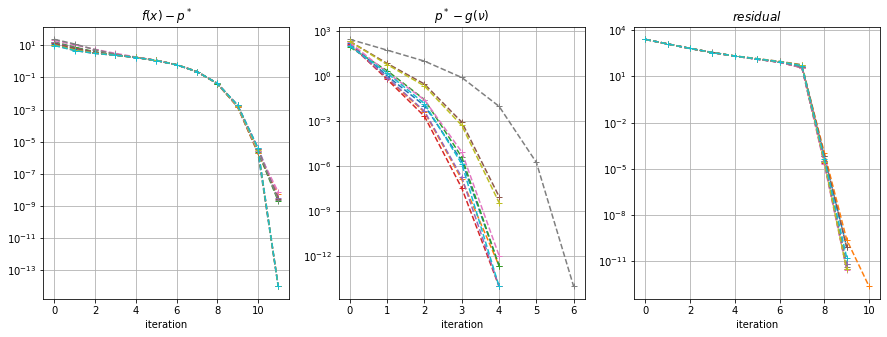

In [26]:
if __name__ == "__main__":
    plt.figure(figsize=(15, 5))
    ax = plt.subplot(1, 3, 1)
    solve_by_newton_method_with_equality_constraints(ax, n=500, m=100, num_episodes=10, seed=2)

    ax = plt.subplot(1, 3, 2)
    solve_by_newton_method_to_dual_problem(ax, n=500, m=100, num_episodes=10, seed=2)

    ax = plt.subplot(1, 3, 3)
    solve_by_infeasible_start_newton_method(ax, n=500, m=100, num_episodes=10, seed=2)

    plt.show()